In [3]:
!pip install seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../datasets/cleaned/crop_production_clean.csv")

df.head()

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,Yield
0,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Arecanut,1254.0,2000.0,1.594896
1,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Other Kharif Pulses,2.0,1.0,0.500000
2,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Rice,102.0,321.0,3.147059
3,Andaman And Nicobar Islands,Nicobars,2000,Whole Year,Banana,176.0,641.0,3.642045
4,Andaman And Nicobar Islands,Nicobars,2000,Whole Year,Cashewnut,720.0,165.0,0.229167


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("States:", df["State_Name"].nunique())
print("Districts:", df["District_Name"].nunique())
print("Crops:", df["Crop"].nunique())
print("Seasons:", df["Season"].nunique())

print("Years:", df["Crop_Year"].min(), "-", df["Crop_Year"].max())

Rows: 242361
Columns: 8
States: 33
Districts: 646
Crops: 124
Seasons: 6
Years: 1997 - 2015


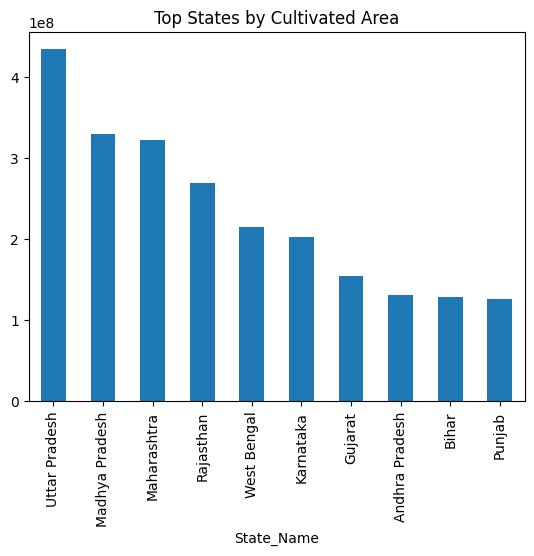

In [6]:
state_area = (
    df.groupby("State_Name")["Area"]
      .sum()
      .sort_values(ascending=False)
)

state_area.head(10).plot(kind="bar")
plt.title("Top States by Cultivated Area")
plt.show()

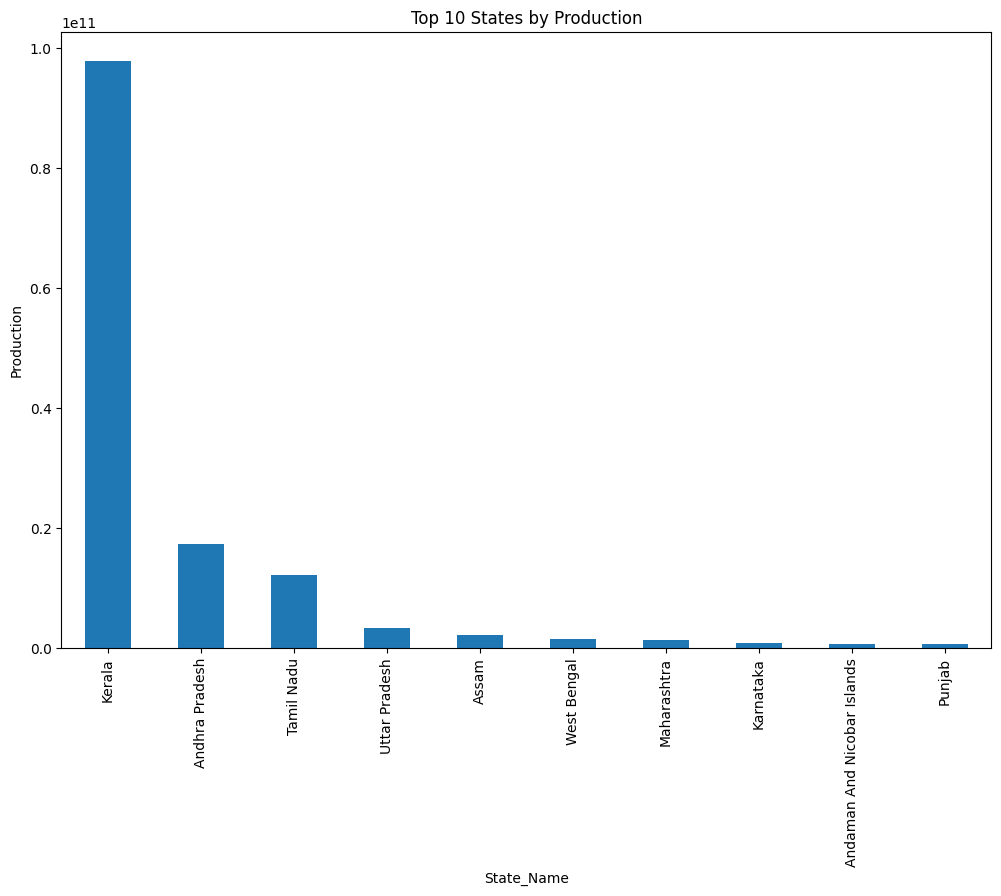

In [7]:
state_prod = (
    df.groupby("State_Name")["Production"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12,8))
state_prod.head(10).plot(kind="bar")
plt.title("Top 10 States by Production")
plt.ylabel("Production")
plt.show()

Kerala records the highest total production in the dataset, significantly exceeding other states. This suggests that one or more high-production crops may be dominating the aggregated production. Further crop-wise analysis is required to identify the main contributors.

In [8]:
df[df["State_Name"] == "Kerala"] \
    .groupby("Crop")["Production"] \
    .sum() \
    .sort_values(ascending=False) \
    .head(20)

Crop
Coconut         9.780304e+10
Tapioca         4.611366e+07
Rice            1.059335e+07
Banana          7.655662e+06
Sugarcane       3.819916e+06
Arecanut        1.893642e+06
Mango           1.650151e+06
Rubber          1.175267e+06
Black Pepper    9.715301e+05
Cashewnut       9.483952e+05
Dry Ginger      6.010938e+05
Papaya          2.676750e+05
Pineapple       2.633810e+05
Cardamom        1.363420e+05
Coffee          1.300120e+05
Turmeric        1.243639e+05
Tea             1.210793e+05
Sweet Potato    1.192310e+05
Garlic          9.225500e+04
Drum Stick      7.711300e+04
Name: Production, dtype: float64

In [9]:
df[df["Crop"] == "Coconut"] \
    .groupby("State_Name")["Production"] \
    .sum() \
    .sort_values(ascending=False)

State_Name
Kerala                         9.780304e+10
Andhra Pradesh                 1.680600e+10
Tamil Nadu                     1.093774e+10
Assam                          1.954408e+09
West Bengal                    7.178412e+08
Andaman And Nicobar Islands    7.177900e+08
Goa                            5.031126e+08
Puducherry                     3.791390e+08
Telangana                      1.056730e+08
Karnataka                      5.676710e+07
Dadra And Nagar Haveli         1.172880e+05
Mizoram                        4.000000e+01
Name: Production, dtype: float64

Observation: Coconut production dominates the aggregated production statistics, particularly in Kerala. This suggests that production values across different crops may use different measurement units (e.g., number of coconuts versus tons), making direct aggregation across all crop types less meaningful. Future analyses should primarily compare production within the same crop.

In [10]:
df.groupby("State_Name")[["Area", "Production"]] \
    .sum() \
    .sort_values(by="Production", ascending=False) \
    .head(10)

,Area,Production
State_Name,,
Kerala,3.180225e+07,9.788005e+10
Andhra Pradesh,1.315073e+08,1.732459e+10
Tamil Nadu,9.541695e+07,1.207644e+10
Uttar Pradesh,4.336223e+08,3.234493e+09
Assam,7.037875e+07,2.111752e+09
West Bengal,2.154030e+08,1.397904e+09
Maharashtra,3.221860e+08,1.263641e+09
Karnataka,2.029086e+08,8.634298e+08
Andaman And Nicobar Islands,3.370834e+05,7.182232e+08


In [11]:
plt.figure(figsize=(8,5))

ax = season_prod.plot(kind="bar")

plt.title("Cultivated Area by Season")
plt.ylabel("Area (Hectares)")
plt.xlabel("Season")
plt.xticks(rotation=45)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height()/1e9:.2f}B',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

NameError: name 'season_prod' is not defined

<Figure size 800x500 with 0 Axes>

Observation: Kharif accounts for the largest cultivated area in the dataset, followed by Rabi. This aligns with India's agricultural cycle, where the monsoon season supports extensive cultivation. Whole Year crops occupy a moderate share due to perennial crops such as coconut, banana, tea, and sugarcane.

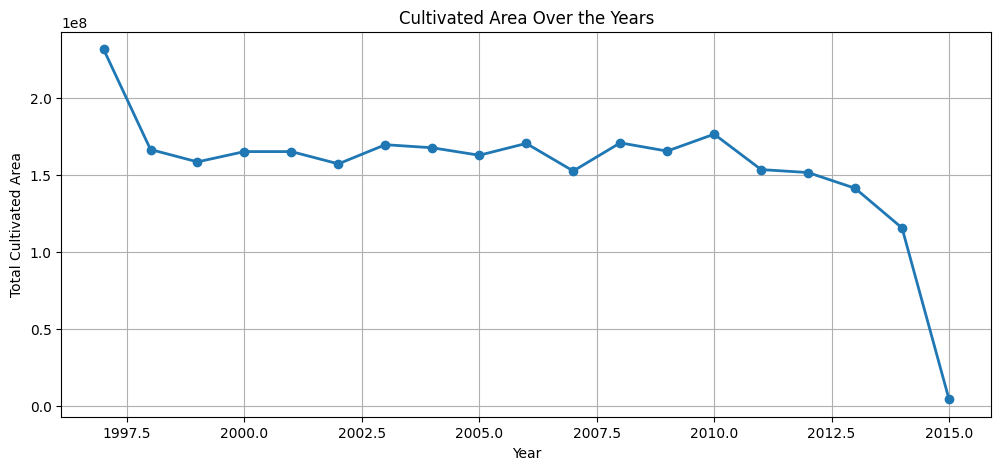

In [ ]:
yearly_area = (
    df.groupby("Crop_Year")["Area"]
      .sum()
)

plt.figure(figsize=(12,5))

plt.plot(
    yearly_area.index,
    yearly_area.values,
    marker='o',
    linewidth=2
)

plt.title("Cultivated Area Over the Years")
plt.xlabel("Year")
plt.ylabel("Total Cultivated Area")
plt.grid(True)

plt.show()

In [ ]:
df["Crop_Year"].value_counts().sort_index()

Crop_Year
1997     8899
1998    11262
1999    12441
2000    13553
2001    13293
2002    16536
2003    17139
2004    13858
2005    13519
2006    13976
2007    14269
2008    14230
2009    13767
2010    13793
2011    13791
2012    13184
2013    13475
2014    10815
2015      561
Name: count, dtype: int64

Observation: The dataset contains a significant reduction in the number of records for 2015 (561 records compared to approximately 13,000–17,000 in previous years). Consequently, the sharp decline in cultivated area observed in 2015 is likely due to incomplete data collection rather than an actual reduction in agricultural activity. Therefore, 2015 will be excluded from forecasting experiments to avoid introducing bias into the predictive models.

In [ ]:
forecast_df = df[df["Crop_Year"] < 2015]

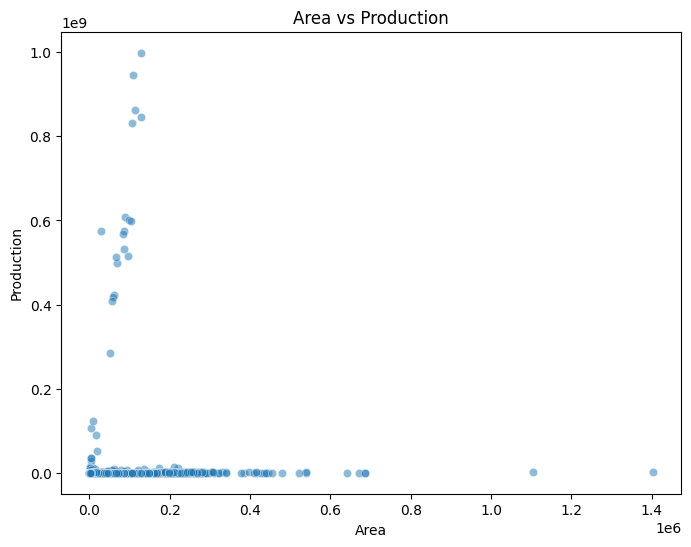

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df.sample(10000, random_state=42),  # sample for faster plotting
    x="Area",
    y="Production",
    alpha=0.5
)

plt.title("Area vs Production")
plt.show()

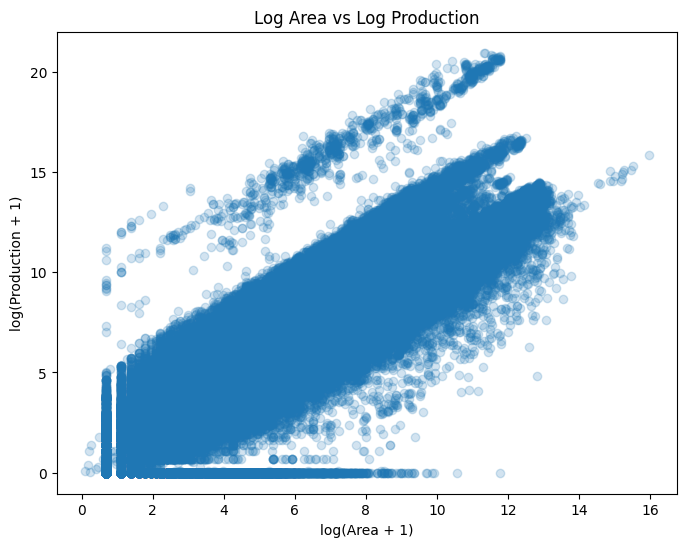

In [ ]:
import numpy as np

plt.figure(figsize=(8,6))

plt.scatter(
    np.log1p(df["Area"]),
    np.log1p(df["Production"]),
    alpha=0.2
)

plt.title("Log Area vs Log Production")
plt.xlabel("log(Area + 1)")
plt.ylabel("log(Production + 1)")
plt.show()

Observation: The raw Area vs Production scatter plot is heavily influenced by extreme values and is difficult to interpret. After applying a logarithmic transformation, a clear positive relationship emerges between cultivated area and production. Multiple diagonal clusters are visible, indicating that different crop types have distinct production characteristics and yields. This suggests that crop type should be included as a key feature in forecasting models.

In [ ]:
df[["Area", "Production"]].corr()

,Area,Production
Area,1.000000,0.040587
Production,0.040587,1.000000


In [ ]:
import numpy as np

log_df = df.copy()

log_df["Log_Area"] = np.log1p(log_df["Area"])
log_df["Log_Production"] = np.log1p(log_df["Production"])

log_df[["Log_Area", "Log_Production"]].corr()

,Log_Area,Log_Production
Log_Area,1.000000,0.879198
Log_Production,0.879198,1.000000


Observation: The correlation between raw cultivated area and production is only 0.04, indicating that the relationship is obscured by highly skewed data and differing crop scales. After applying a logarithmic transformation, the correlation increases to 0.879, revealing a strong positive relationship. This demonstrates that cultivated area is an important predictor of production when the data distribution is normalized.

## Key Insights

1. The dataset contains 242,361 cleaned records covering 33 states, 646 districts, and 124 crops from 1997–2015.

2. Approximately 1.5% of records had missing production values and were removed because production is the target variable.

3. Kerala has the highest total production, primarily due to coconut, whose production dominates aggregated totals.

4. Aggregating production across different crop types can be misleading because crops may have different reporting units and production scales.

5. Kharif season accounts for the largest cultivated area, followed by Rabi, reflecting India's agricultural calendar.

6. Cultivated area remains relatively stable from 1998 to 2013. The sharp decline in 2015 is caused by incomplete data (only 561 records) and should be excluded during forecasting.

7. The raw correlation between Area and Production is very low (0.04) due to skewness and heterogeneous crop types.

8. After logarithmic transformation, the correlation increases to 0.879, indicating a strong positive relationship between cultivated area and production.

9. Crop type, cultivated area, weather, season, and location are expected to be key features for production forecasting.

In [12]:
df.columns.tolist()

['State_Name',
 'District_Name',
 'Crop_Year',
 'Season',
 'Crop',
 'Area',
 'Production',
 'Yield']